In [46]:
from unittest import result

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [47]:
wine = load_wine()
df = pd.DataFrame(
    wine.data,
    columns= wine.feature_names
)
df['target'] = wine.target
df.sample(n=5)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
23,12.85,1.60,2.52,17.8,95.0,2.48,2.37,0.26,1.46,3.93,1.09,3.63,1015.0,0
112,11.76,2.68,2.92,20.0,103.0,1.75,2.03,0.60,1.05,3.80,1.23,2.50,607.0,1
155,13.17,5.19,2.32,22.0,93.0,1.74,0.63,0.61,1.55,7.90,0.60,1.48,725.0,2
85,12.67,0.98,2.24,18.0,99.0,2.20,1.94,0.30,1.46,2.62,1.23,3.16,450.0,1
75,11.66,1.88,1.92,16.0,97.0,1.61,1.57,0.34,1.15,3.80,1.23,2.14,428.0,1


In [48]:
X = wine.data
y = wine.target

# Informations sur le dataset
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)
print("Caracteristiques :", wine.feature_names )
print("Classes :", wine.target_names )

Dimensions de X : (178, 13)
Dimensions de y : (178,)
Caracteristiques : ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Classes : ['class_0' 'class_1' 'class_2']


In [49]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=262002,stratify=y)
print("X_train :", X_train.shape)
print("X_test :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test :", y_test.shape)

X_train : (142, 13)
X_test : (36, 13)
y_train : (142,)
y_test : (36,)


In [50]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


In [51]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  target          

In [52]:
df.isna().sum()

alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64

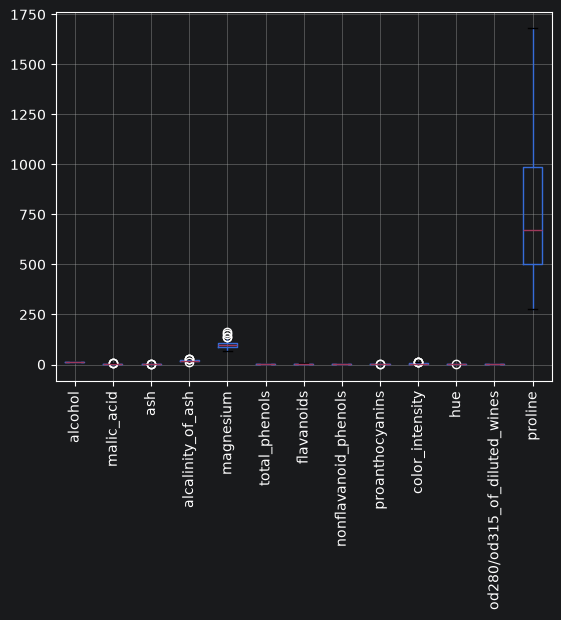

In [53]:
df.drop(columns='target').select_dtypes(include='number').boxplot()
plt.xticks(rotation=90)
plt.show()

In [54]:
knn = KNeighborsClassifier(metric='euclidean')
knn.fit(X_train,y_train)

,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [55]:
y_pred = knn.predict(X_test)
print('accuracy without normalisation:',accuracy_score(y_test,y_pred))

accuracy without normalisation: 0.6666666666666666


In [56]:
#preprocessing
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_sec = scaler.fit_transform(X_train)
X_test_sec = scaler.transform(X_test)
knn2 = KNeighborsClassifier(metric='euclidean')
knn2.fit(X_train_sec,y_train)
y_pred = knn2.predict(X_test_sec)
print('accuracy with normalisation:',accuracy_score(y_test,y_pred))

accuracy with normalisation: 1.0


In [57]:
metric = ['euclidean','minkowski','chebyshev','manhattan']
result = []

for i in metric:
    knn2 = KNeighborsClassifier(metric=i)
    knn2.fit(X_train_sec,y_train)
    y_pred = knn2.predict(X_test_sec)
    acc = accuracy_score(y_test,y_pred)
    result.append(acc)

for i,z in zip(metric,result):
    print('the metric ',i,'have accuracy of ',z)

print(result)

the metric  euclidean have accuracy of  1.0
the metric  minkowski have accuracy of  1.0
the metric  chebyshev have accuracy of  0.9444444444444444
the metric  manhattan have accuracy of  0.9722222222222222
[1.0, 1.0, 0.9444444444444444, 0.9722222222222222]


<h5>Quelle métrique de distance fournit la meilleure performance ?</h5><br>
the metric  euclidean have accuracy of  0.9166666666666666
the metric  minkowski have accuracy of  0.9166666666666666

In [58]:
metric1 = range(2,16)
resultM = []

for i in metric1:
    knn2 = KNeighborsClassifier(metric='minkowski',n_neighbors=i)
    knn2.fit(X_train_sec,y_train)
    knn2.fit(X_train_sec,y_train)
    y_pred = knn2.predict(X_test_sec)
    acc = accuracy_score(y_test,y_pred)
    resultM.append(acc)

for i,z in zip(metric,result):
    print('the n_neighbors ',i,'have accuracy of ',z)

print(result)

the n_neighbors  euclidean have accuracy of  1.0
the n_neighbors  minkowski have accuracy of  1.0
the n_neighbors  chebyshev have accuracy of  0.9444444444444444
the n_neighbors  manhattan have accuracy of  0.9722222222222222
[1.0, 1.0, 0.9444444444444444, 0.9722222222222222]


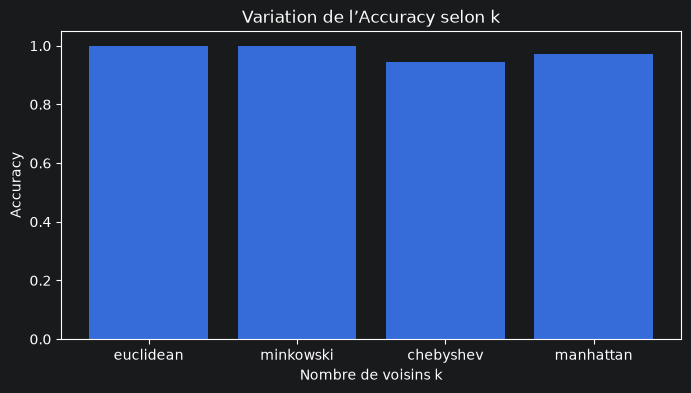

In [59]:
plt.figure(figsize =(8, 4))
plt.bar(metric,result)
plt.xlabel("Nombre de voisins k")
plt.ylabel("Accuracy")
plt.title("Variation de l’Accuracy selon k")
plt.show()

In [60]:
dict_knei = zip(metric1,resultM)
max(dict_knei)

(15, 0.9722222222222222)

In [61]:
dict_metric = zip(metric,result)
max(dict_metric)

('minkowski', 1.0)

In [65]:
knn_final = KNeighborsClassifier(metric='minkowski',n_neighbors=2)
knn_final.fit(X_train_sec,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",2
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [64]:
from sklearn.metrics import (
 accuracy_score ,
 precision_score ,
 recall_score ,
 f1_score ,
 classification_report ,
 confusion_matrix
 )
import seaborn as sns

In [74]:
y_pred_final = knn_final.predict( X_test_sec )
classification_report_final = classification_report(y_test,y_pred_final,target_names =wine. target_names)

In [75]:
print(classification_report_final)

              precision    recall  f1-score   support

     class_0       0.92      1.00      0.96        12
     class_1       1.00      0.93      0.96        14
     class_2       1.00      1.00      1.00        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



In [77]:
confusion_matrix_final = confusion_matrix(y_test,y_pred_final)
print(confusion_matrix_final)

[[12  0  0]
 [ 1 13  0]
 [ 0  0 10]]


<Figure size 600x400 with 0 Axes>

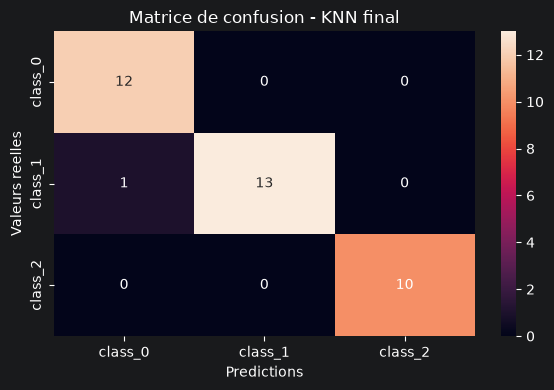

In [79]:
plt.figure(figsize =(6, 4))
sns.heatmap(
 confusion_matrix_final ,
 annot=True ,
   fmt="d",
   xticklabels =wine.target_names ,
   yticklabels =wine.target_names
 )
plt.xlabel("Predictions")
plt.ylabel("Valeurs reelles")
plt.title("Matrice de confusion - KNN final")
plt. tight_layout ()
plt.show ()
